# 02 · Backtest L2 su FI-2010 (E1, E2)

Stessi snapshot, stessa strategia; cambia solo la regola che decide se una quota passiva è eseguita:

| Regola | Condizione per un acquisto al prezzo *p* | Ruolo |
|---|---|---|
| `touch` | best bid ≤ *p* | baseline ottimistica (E1) |
| `price-through` | best bid < *p* | baseline L2 prudenziale (E2) |
| `cross` | best ask ≤ *p* | baseline aggiuntiva sul lato opposto |

FI-2010 non contiene ordini individuali: il confronto con la coda FIFO avviene su ITCH e Hyperliquid (notebook 04 e 05). I prezzi sono normalizzati, quindi il P&L è in unità DecPre e i costi non sono applicabili.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")
validation = R.load(ROOT, "validation")
selected = R.load_json(ROOT, "selected_params")

display(Markdown("**Validazione**: P&L medio per sessione con `price-through` (giorni 2-3; soglie dal giorno 1)"))
display(R.validation_grid(validation, "fi2010", "final_equity").style.format("{:.4f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"Parametri scelti in validazione: `{selected['fi2010']['params']}`."))
stats = R.model_table(test, "fi2010")
display(stats.round(4))

**Validazione**: P&L medio per sessione con `price-through` (giorni 2-3; soglie dal giorno 1)

Parametri scelti in validazione: `{'vol_quantile': 0.9, 'max_order_age_events': 200, 'volatility_window': 100}`.

,sessioni,media,ic95_basso,ic95_alto,quota_positive
touch,35,0.3715,0.2435,0.5294,1.0
price-through,35,-0.0044,-0.0073,-0.0018,0.2
cross,35,-0.0141,-0.0184,-0.0102,0.0


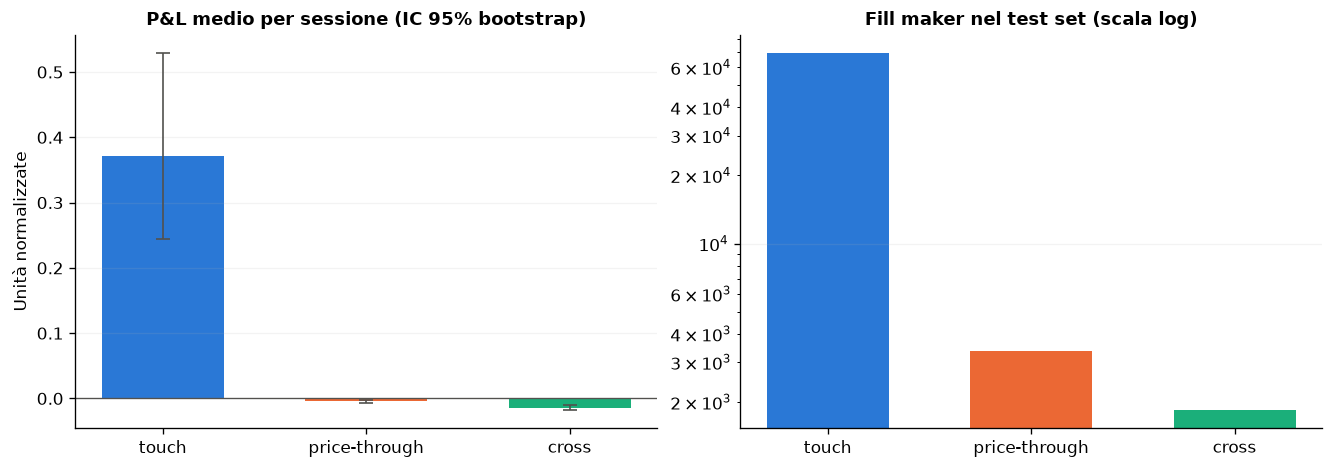

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
R.bar_by_model(axes[0], stats, "P&L medio per sessione (IC 95% bootstrap)", "Unità normalizzate")
fills = test[test.dataset == "fi2010"].groupby("model").maker_fills.sum().reindex(["touch", "price-through", "cross"])
axes[1].bar([R.LABELS[m] for m in fills.index], fills, color=[R.COLORS[m] for m in fills.index], width=0.6)
axes[1].set(yscale="log", title="Fill maker nel test set (scala log)")
axes[1].grid(axis="x", visible=False)
fig.savefig(FIGURES / "fi2010_test.png", dpi=180, bbox_inches="tight")
plt.show()

## Esiti delle coppie e scomposizione del P&L

*Bilaterale*: entrambi i lati eseguiti (lo spread è incassato). *Unilaterale*: un solo lato, poi liquidazione alla scadenza. L'**edge maker** confronta il prezzo di esecuzione con il midpoint al momento del fill: è negativo quando la regola esegue la quota a un prezzo già superato dal mercato.

In [3]:
display(R.fill_rates(test, "fi2010").style.format({"coppie": "{:,.0f}", **{c: "{:.1%}" for c in ["bilaterali", "unilaterali", "senza fill", "con fill parziale"]}}))
display(R.decomposition(test, "fi2010").round(5))
by_day = test[test.dataset == "fi2010"].pivot_table(index="session", columns="model", values="final_equity", aggfunc="sum")
display(by_day[["touch", "price-through", "cross"]].round(4))

,coppie,bilaterali,unilaterali,senza fill,con fill parziale
touch,"35,338",96.8%,3.2%,0.0%,0.0%
price-through,"2,466",41.5%,53.2%,5.3%,0.0%
cross,"1,958",16.6%,60.4%,23.0%,0.0%


,maker_edge,liquidation_cost,inventory_pnl,final_equity,adverse_selection
touch,0.37906,-0.00589,-0.00172,0.37145,0.00075
price-through,0.00683,-0.00710,-0.00418,-0.00445,-0.00263
cross,-0.00740,-0.00600,-0.00066,-0.01406,-0.00068


model,touch,price-through,cross
session,,,
day04,1.1814,-0.0167,-0.0609
day05,1.1809,-0.0182,-0.0822
day06,2.0090,-0.0309,-0.0789
day07,1.1847,-0.0262,-0.0659
day08,3.1487,-0.0328,-0.0775
day09,2.9671,-0.0279,-0.0852
day10,1.3290,-0.0030,-0.0414


## Contributo del filtro di volatilità

Le stesse sessioni di test sono ripetute con la strategia sempre attiva (ablazione). La differenza è appaiata per sessione, con intervallo bootstrap al 95%.

In [4]:
ablation = R.load(ROOT, "ablation")
effect = R.filter_effect(test, ablation, "fi2010", "final_equity")
display(effect.style.format({c: "{:.4f}" for c in ["con filtro", "sempre attiva", "differenza", "IC95 basso", "IC95 alto"]}
        | {"sessioni migliori con filtro": "{:.0%}", "quota record attivi": "{:.0%}", "fill con filtro": "{:,.0f}",
           "fill sempre attiva": "{:,.0f}", "liquidazioni per volatilità": "{:.1f}"}))

,sessioni,con filtro,sempre attiva,differenza,IC95 basso,IC95 alto,sessioni migliori con filtro,quota record attivi,fill con filtro,fill sempre attiva,liquidazioni per volatilità
modello,,,,,,,,,,,
touch,35,0.3715,0.3535,0.0179,-0.0054,0.0416,63%,85%,"1,987","1,842",16.8
price-through,35,-0.0044,-0.0026,-0.0019,-0.0033,-0.0004,23%,85%,96,92,17.0
cross,35,-0.0141,-0.0141,0.0000,-0.0015,0.0016,46%,85%,52,56,12.3


In [5]:
s = stats
display(Markdown(
    f"**Esito.** Con `touch` il P&L medio per sessione è {it(s.loc['touch', 'media'], 4)} (positivo nel "
    f"{pct(s.loc['touch', 'quota_positive'], 0)} delle sessioni); con `price-through` è {it(s.loc['price-through', 'media'], 4)} "
    f"(positivo nel {pct(s.loc['price-through', 'quota_positive'], 0)}) e con `cross` {it(s.loc['cross', 'media'], 4)} "
    f"(positivo nel {pct(s.loc['cross', 'quota_positive'], 0)}). La sola scelta della regola L2 cambia il segno del risultato."))

**Esito.** Con `touch` il P&L medio per sessione è 0,3715 (positivo nel 100% delle sessioni); con `price-through` è -0,0044 (positivo nel 20%) e con `cross` -0,0141 (positivo nel 0%). La sola scelta della regola L2 cambia il segno del risultato.